# 🛡️ UniShield: AI-Generated Content Detection (AIGCD)
### Replicating CVPR Findings 2026 Paper: *"UniShield: An Adaptive Multi-Agent Framework for Unified Forgery Image Detection and Localization"*

---
### 📌 Overview for AIGCD Track
- **Target Task:** Whole-Image Synthetic / AI-Generated Image Detection (Real vs AI-Generated).
- **Dataset:** `sohaibkhatak/ai-vs-human-generated-images` (contains both `train` and `test` data with `AI` and `Human` folders).
- **Selected Model Backbone:** **ResNet-50** with ImageNet-1K V2 pretrained weights (as requested by supervisor & evaluated in Table 2 of CVPR 2026 paper), with option to switch to **AIDE** (Dual-stream Patch + Frequency Spectrum).
- **Evaluation Protocol:** **5-Fold Cross-Validation where every fold uses an 80% Train / 10% Validation / 10% Test split**, **5 Epochs per fold** (25 epochs in total).
- **Key Metrics:** Accuracy (ACC), F1-Score, AUC, Precision, Recall.

## 🔗 Section 1: Kaggle Dataset Loading & Configuration
> **Dataset:** `sohaibkhatak/ai-vs-human-generated-images`
>
> **Option A (Attached Dataset in Kaggle):** If you attached the dataset via **'+ Add Data'**, it is automatically resolved from `/kaggle/input/ai-vs-human-generated-images`.
> 
> **Option B (Direct Download with kagglehub):** The cell below will also download it automatically via `kagglehub` if not already present!

> ⚙️ **GPU note:** set *Settings → Accelerator → GPU T4 x2*. This notebook moves the model + data to the GPU, splits each batch across both T4s with `DataParallel`, and uses fp16 mixed precision.

In [1]:
# NOTE: torch/torchvision are NOT reinstalled on purpose - Kaggle ships CUDA-enabled builds and
# pip-installing them can replace them with a build that cannot see the GPU.
!pip install -q kagglehub tabulate

# Quick sanity check for hardware accelerator
import torch
print(f"⚡ PyTorch CUDA Available: {torch.cuda.is_available()}")
N_GPUS = torch.cuda.device_count()
print(f"🔢 Number of active GPUs : {N_GPUS}")
for _i in range(N_GPUS):
    print(f"   GPU {_i}: {torch.cuda.get_device_name(_i)}")
if N_GPUS == 0:
    print("⚠️ Running on CPU. Settings -> Accelerator -> 'GPU T4 x2', then restart the session.")
elif N_GPUS == 1:
    print("ℹ️ Only 1 GPU attached - training will use it. (Pick 'GPU T4 x2' to use both.)")
else:
    print("✅ Multiple GPUs detected - training will be split across all of them (DataParallel).")

import os
from pathlib import Path

# ==============================================================================
# 🔍 SECTION 1: BULLETPROOF DYNAMIC DATASET DISCOVERY FOR KAGGLE
# ==============================================================================
# Manual Override: If your dataset is mounted at a specific custom path, set it here:
MANUAL_DATA_DIR = ""  # e.g. "/kaggle/input/ai-vs-human-generated-dataset"

def find_aigcd_dataset_path():
    """
    Ultra-resilient crawler for Kaggle input and local directories.
    Handles '/kaggle/input/datasets', '/kaggle/input/ai-vs-human-generated-dataset',
    CIFAKE, AIGCDetectBenchmark, or any attached input dataset.
    """
    if MANUAL_DATA_DIR and os.path.exists(MANUAL_DATA_DIR):
        print(f"✅ Using manual dataset override: {MANUAL_DATA_DIR}")
        return MANUAL_DATA_DIR

    if not os.path.exists('/kaggle/input'):
        for lp in ['./data/ai-vs-human-generated-dataset', './data/ai-vs-human-generated-images', './data/AIGCD']:
            if os.path.exists(lp):
                print(f"✅ Discovered local dataset at: {lp}")
                return lp
        return None

    available = os.listdir('/kaggle/input')
    print(f"📂 Available datasets in /kaggle/input: {available}")

    if len(available) == 0:
        print("🚨 No dataset attached! In Kaggle right panel, click '+ Add Input' and attach 'ai-vs-human-generated-dataset'.")
        return None

    # Priority 1: Deep scan across all folders in /kaggle/input for train.csv or images
    for root, dirs, files in os.walk('/kaggle/input'):
        has_csv = any(f.lower() in ['train.csv', 'data.csv', 'metadata.csv', 'labels.csv'] for f in files)
        has_img_dir = any(d.lower() in ['train_data', 'train', 'human', 'ai', 'real', 'fake'] for d in dirs)
        if has_csv or has_img_dir:
            print(f"✅ Crawler auto-detected dataset root at: {root}")
            return root

    # Priority 2: Match known candidate paths
    candidates = [
        '/kaggle/input/ai-vs-human-generated-dataset',
        '/kaggle/input/ai-vs-human-generated-images',
        '/kaggle/input/datasets/alessandrasala79/ai-vs-human-generated-dataset',
        '/kaggle/input/datasets/ai-vs-human-generated-dataset',
        '/kaggle/input/datasets',
        '/kaggle/input/cifake-real-and-ai-generated-synthetic-images',
        '/kaggle/input/aigcdetectbenchmark',
        '/kaggle/input/ai-generated-images-dataset',
    ]
    for c in candidates:
        if os.path.exists(c):
            print(f"✅ Discovered dataset at: {c}")
            return c

    # Priority 3: Match by name keywords
    for item in available:
        low = item.lower()
        if any(k in low for k in ['ai-vs-human', 'human', 'ai-generated', 'cifake', 'aigc', 'synthetic']):
            cand = os.path.join('/kaggle/input', item)
            print(f"✅ Matched AIGCD dataset: {cand}")
            return cand

    # Priority 4: Fallback to first available attached dataset
    cand = os.path.join('/kaggle/input', available[0])
    print(f"ℹ️ Using first available dataset in /kaggle/input: {cand}")
    return cand

DATA_DIR = find_aigcd_dataset_path()

if DATA_DIR is None:
    try:
        import kagglehub
        print("📥 Attempting automatic download via kagglehub ('alessandrasala79/ai-vs-human-generated-dataset')...")
        DATA_DIR = kagglehub.dataset_download("alessandrasala79/ai-vs-human-generated-dataset")
        print(f"✅ Downloaded to: {DATA_DIR}")
    except Exception as e:
        print(f"⚠️ kagglehub download note: {e}")
        DATA_DIR = None

ALLOW_SYNTHETIC_FALLBACK = False  # NEVER silently fake data! Raises clear error if dataset is missing.

# ==========================================================================
# ⚙️ TRAINING CONFIGURATION (SUPERVISOR SPECIFICATIONS)
# ==========================================================================
MODEL_CHOICE = "resnet50"   # Options: 'resnet50' (Teacher/Table 2) or 'aide' (Table 1)
DATASET_SPLIT = "all"       # Options: 'all' (train + test merged, then re-split 80/10/10), 'train', or 'test'
MAX_SAMPLES = None          # Set to None for ALL ~80,000 samples, or e.g. 10000 for faster verification
N_FOLDS = 5                 # 5-fold cross-validation
EPOCHS_PER_FOLD = 5         # 5 Epochs for EVERY fold
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.80, 0.10, 0.10   # 80% train / 10% validation / 10% test
SPLIT_SEED = 42             # same seed -> reproducible folds
BATCH_SIZE_PER_GPU = 64     # ResNet-50 in fp16 fits easily on a 16 GB T4
BATCH_SIZE = BATCH_SIZE_PER_GPU * max(1, N_GPUS)   # total batch, split across the GPUs by DataParallel
OUT_DIR = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'   # writable output folder
LEARNING_RATE = 1e-4 if MODEL_CHOICE == "resnet50" else 2e-4


⚡ PyTorch CUDA Available: True
🔢 Number of active GPUs : 2
   GPU 0: Tesla T4
   GPU 1: Tesla T4
✅ Multiple GPUs detected - training will be split across all of them (DataParallel).
📂 Available datasets in /kaggle/input: ['datasets']
✅ Crawler auto-detected dataset root at: /kaggle/input/datasets/sohaibkhatak/ai-vs-human-generated-images


## 📦 Section 2: Model Architectures (ResNet-50 & AIDE Expert Detector)

In [2]:
import cv2
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, precision_score, recall_score
import matplotlib.pyplot as plt
import pandas as pd
import torchvision.models as models
from tqdm.auto import tqdm
import os
import gc

# ==============================================================================
# 🚀 GPU SETUP: single GPU / dual T4 (DataParallel) + mixed precision
# ==============================================================================
print("=" * 80)
print("🔍 UNI-SHIELD HARDWARE ACCELERATOR VERIFICATION (KAGGLE OPTIMIZED)")
print("=" * 80)

cv2.setNumThreads(0)   # avoid OpenCV oversubscribing CPU threads inside DataLoader workers

if torch.cuda.is_available():
    device = torch.device('cuda:0')
    NUM_GPUS = torch.cuda.device_count()
    for i in range(NUM_GPUS):
        p = torch.cuda.get_device_properties(i)
        print(f"✅ GPU {i}: {p.name} | {p.total_memory / 1024**3:.1f} GB VRAM | compute {p.major}.{p.minor}")
    print(f"   • PyTorch CUDA Version : {torch.version.cuda}")

    torch.backends.cudnn.benchmark = True          # auto-tune fastest conv algorithms
    USE_AMP = True                                  # fp16 mixed precision (T4 tensor cores)
    NUM_WORKERS = min(4, os.cpu_count() or 2)       # Kaggle gives 4 vCPUs
    PIN_MEMORY = True
    print(f"   • Mixed precision (AMP): {USE_AMP}")
    print(f"   • DataLoader           : num_workers={NUM_WORKERS}, pin_memory=True")
    print(f"   • Multi-GPU            : {'DataParallel across ' + str(NUM_GPUS) + ' GPUs' if NUM_GPUS > 1 else 'single GPU'}")
else:
    device = torch.device('cpu')
    NUM_GPUS = 0
    USE_AMP = False
    NUM_WORKERS = 2
    PIN_MEMORY = False
    print("🚨 GPU IS NOT ACTIVE - running on CPU (very slow).")
    print("   Fix: Settings -> Accelerator -> 'GPU T4 x2' (or P100), then restart the session and re-run.")

print(f"🎯 Target PyTorch Device: {device}")
print("=" * 80)
print()

# Normalisation is done ON THE GPU (the DataLoader only returns uint8 images, which is 4x lighter to
# move around and removes a big CPU bottleneck).
_MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def gpu_prepare(imgs_uint8):
    x = imgs_uint8.to(device, non_blocking=True).float().div_(255.0)
    x = (x - _MEAN) / _STD
    return x.contiguous(memory_format=torch.channels_last)

class AutocastWrapper(nn.Module):
    """autocast is thread-local, and DataParallel runs each replica in its own thread,
    so autocast must live INSIDE forward() for mixed precision to work on both GPUs."""
    def __init__(self, module, enabled=True):
        super().__init__()
        self.module = module
        self.enabled = enabled
    def forward(self, x):
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=self.enabled):
            return self.module(x)

def build_model(model_name):
    """Create the model, move it to the GPU, and wrap it in DataParallel when >1 GPU is available."""
    m = create_aigcd_model(model_name)
    m = m.to(device).to(memory_format=torch.channels_last)
    m = AutocastWrapper(m, enabled=USE_AMP)
    if NUM_GPUS > 1:
        m = nn.DataParallel(m)          # splits every batch across all GPUs
    return m

def unwrap(m):
    """Return the raw model (for saving checkpoints) regardless of DataParallel / autocast wrappers."""
    if isinstance(m, nn.DataParallel):
        m = m.module
    return m.module if isinstance(m, AutocastWrapper) else m


# ==========================================================================
# 1. ResNet-50 Binary Classification Model (Teacher/Supervisor Choice)
# ==========================================================================
class ResNet50Detector(nn.Module):
    """
    Standard ResNet-50 Binary Classification Backbone for AIGCD (AI vs Human).
    Uses ImageNet-1K V2 modern pretrained weights (80.86% top-1 accuracy).
    Safely handles offline Kaggle sessions (Internet OFF) without crashing.
    """
    def __init__(self, pretrained=True):
        super().__init__()
        loaded = False
        if pretrained:
            try:
                from torchvision.models import ResNet50_Weights
                weights = ResNet50_Weights.DEFAULT
                self.backbone = models.resnet50(weights=weights)
                loaded = True
            except Exception as e:
                print(f"ℹ️ Online ResNet-50 weights download note ({e}). Attempting cached/fallback...")
                try:
                    self.backbone = models.resnet50(pretrained=True)
                    loaded = True
                except Exception as e2:
                    print(f"⚠️ Offline mode active: Initializing ResNet-50 without online pretraining ({e2}).")
                    self.backbone = models.resnet50(weights=None)
                    loaded = True
        if not loaded:
            self.backbone = models.resnet50(weights=None)
            
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_features, 1)
        )

    def forward(self, x):
        return self.backbone(x).squeeze(-1)

# ==========================================================================
# 2. AIDE Dual-Stream Hybrid Model (Paper Table 1 Expert)
# ==========================================================================
class SpectrumBranch(nn.Module):
    def forward(self, x):
        gray = 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]
        fft_shift = torch.fft.fftshift(torch.fft.fft2(gray))
        mag = torch.log(torch.abs(fft_shift) + 1e-6)
        return (mag - mag.mean(dim=(-2, -1), keepdim=True)) / (mag.std(dim=(-2, -1), keepdim=True) + 1e-6)

class AIDEExpertDetector(nn.Module):
    def __init__(self):
        super().__init__()
        self.spec_branch = SpectrumBranch()
        self.patch_net = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=4), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU()
        )
        self.freq_net = nn.Sequential(
            nn.Conv2d(1, 32, 7, stride=4, padding=3), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU()
        )
        self.fusion = nn.MultiheadAttention(embed_dim=256, num_heads=4, batch_first=True)
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)), nn.Flatten(),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2), nn.Linear(128, 1)
        )
    def forward(self, x):
        f_p = self.patch_net(x)
        f_f = self.freq_net(self.spec_branch(x))
        fused = torch.cat([f_p, f_f], dim=1)
        B, C, H, W = fused.shape
        flat = fused.flatten(2).permute(0, 2, 1)
        attn, _ = self.fusion(flat, flat, flat)
        out = (flat + attn).permute(0, 2, 1).view(B, C, H, W)
        return self.classifier(out).squeeze(-1)

# ==========================================================================
# 3. Model Factory Function (UniShield Paper Backbones)
# ==========================================================================
def create_aigcd_model(model_name="resnet50", pretrained=True):
    """
    Factory function to instantiate the requested AIGCD detection backbone:
    - 'resnet50': Standard ResNet-50 Binary Classifier (Paper Table 2 Teacher/Baseline)
    - 'aide': Dual-Stream Frequency + Spatial AIDE Expert (Paper Table 1 Expert)
    """
    m = str(model_name).lower().strip()
    if "resnet" in m:
        return ResNet50Detector(pretrained=pretrained)
    elif "aide" in m:
        return AIDEExpertDetector()
    else:
        return ResNet50Detector(pretrained=pretrained)

create_aigcd_detector = create_aigcd_model


🔍 UNI-SHIELD HARDWARE ACCELERATOR VERIFICATION (KAGGLE OPTIMIZED)
✅ GPU 0: Tesla T4 | 14.6 GB VRAM | compute 7.5
✅ GPU 1: Tesla T4 | 14.6 GB VRAM | compute 7.5
   • PyTorch CUDA Version : 12.8
   • Mixed precision (AMP): True
   • DataLoader           : num_workers=4, pin_memory=True
   • Multi-GPU            : DataParallel across 2 GPUs
🎯 Target PyTorch Device: cuda:0



## 📂 Section 3: Dataset Loader (Supporting Both Train & Test Splits)

In [3]:
GENERATOR_NAMES = [
    'ProGAN', 'StyleGAN', 'BigGAN', 'CycleGAN', 'StarGAN', 'GauGAN',
    'StyleGAN2', 'WFTIR', 'ADM', 'Glide', 'Midjourney', 'SD_v14',
    'SD_v15', 'VQDM', 'Wukong', 'DALLE2'
]

class AIGCDataset(Dataset):
    """
    Ultra-Fast Universal AIGCD Dataset Loader supporting:
    1. CSV-mapped datasets (like 'alessandrasala79/ai-vs-human-generated-dataset' with train.csv)
    2. Folder-structured datasets (like CIFAKE, GenImage, AIGCDetectBenchmark with REAL/FAKE or Human/AI folders)
    3. Deep recursive search for CSV files in subdirectories
    4. Multi-generator attribution tagging
    """
    def __init__(self, data_dir, img_size=224, split="all", max_samples=None):
        self.img_size = img_size
        self.split = split.lower()
        self.samples = []
        
        if data_dir is None or not os.path.exists(data_dir):
            if not ALLOW_SYNTHETIC_FALLBACK:
                raise FileNotFoundError(
                    f"❌ Dataset path does not exist: '{data_dir}'.\n"
                    f"Available in /kaggle/input: {os.listdir('/kaggle/input') if os.path.exists('/kaggle/input') else 'Not on Kaggle'}.\n"
                    f"Please attach the dataset to your Kaggle notebook or set MANUAL_DATA_DIR in Cell 2."
                )
        else:
            p = Path(data_dir)
            print(f"🔍 Scanning AIGCD dataset at: {p.resolve()}")
            
            # -------------------------------------------------------------
            # STRATEGY 1: High-Speed Recursive CSV Metadata Loader
            # -------------------------------------------------------------
            csv_candidates = list(p.rglob('*.csv'))
            csv_candidates.sort(key=lambda x: 0 if 'train' in x.name.lower() else (1 if 'data' in x.name.lower() else 2))
            
            csv_loaded = False
            for csv_path in csv_candidates:
                try:
                    df = pd.read_csv(csv_path)
                    path_col = next((c for c in df.columns if any(k in c.lower() for k in ['file_name', 'filename', 'path', 'filepath', 'image', 'img', 'id'])), None)
                    label_col = next((c for c in df.columns if any(k in c.lower() for k in ['label', 'target', 'class', 'category', 'is_ai'])), None)
                    
                    if path_col and label_col:
                        df = df.dropna(subset=[path_col, label_col])
                        print(f"📄 Found metadata CSV: {csv_path.name} with {len(df)} rows.")
                        print(f"   • Image column: '{path_col}', Label column: '{label_col}'")
                        
                        # Determine directory prefix once using the first valid row (avoids 80,000 slow filesystem calls)
                        sample_row = df.iloc[0]
                        sample_rel = str(sample_row[path_col]).strip()
                        prefix = None
                        strip_dirname = False
                        
                        test_candidates = [
                            (str(p), p / sample_rel),
                            (str(csv_path.parent), csv_path.parent / sample_rel),
                            (str(p / 'train_data'), p / 'train_data' / Path(sample_rel).name),
                            (str(p / 'train'), p / 'train' / Path(sample_rel).name),
                            (str(p / 'images'), p / 'images' / Path(sample_rel).name),
                            (str(csv_path.parent / 'train_data'), csv_path.parent / 'train_data' / Path(sample_rel).name),
                            (str(p), p / Path(sample_rel).name)
                        ]
                        
                        for pref, cand in test_candidates:
                            if cand.is_file():
                                prefix = pref
                                strip_dirname = (cand == (Path(pref) / Path(sample_rel).name))
                                print(f"   • Image path resolved successfully under prefix: '{prefix}'")
                                break
                                
                        if prefix is None:
                            prefix = str(p)
                            
                        # Fast iteration using itertuples (takes <0.2 seconds for 80,000 rows)
                        loaded_from_this_csv = 0
                        for row in df.itertuples():
                            rel_name = str(getattr(row, path_col)).strip()
                            img_file = Path(rel_name).name if strip_dirname else rel_name
                            full_path = os.path.join(prefix, img_file)
                            
                            raw_lbl = str(getattr(row, label_col)).strip().lower()
                            if raw_lbl in ['0', '0.0', 'human', 'real', 'authentic', 'original']:
                                lbl = 0
                                gen = 'Human'
                            elif raw_lbl in ['1', '1.0', 'ai', 'fake', 'synthetic', 'generated']:
                                lbl = 1
                                gen = 'AI_Synthesis'
                            else:
                                try:
                                    lbl = int(float(raw_lbl))
                                    gen = 'AI_Synthesis' if lbl == 1 else 'Human'
                                except Exception:
                                    lbl = 1 if ('ai' in raw_lbl or 'fake' in raw_lbl) else 0
                                    gen = 'AI_Synthesis' if lbl == 1 else 'Human'
                                    
                            if lbl == 1:
                                for g in GENERATOR_NAMES:
                                    if g.lower() in full_path.lower() or g.lower() in raw_lbl:
                                        gen = g
                                        break
                                        
                            s_name = 'train' if 'train' in csv_path.name.lower() or 'train' in full_path.lower() else 'test'
                            if self.split != 'all' and s_name != self.split:
                                continue
                                
                            self.samples.append((full_path, lbl, gen, s_name))
                            loaded_from_this_csv += 1
                            
                        if loaded_from_this_csv > 0:
                            print(f"   ✅ Successfully indexed {loaded_from_this_csv} images via {csv_path.name}")
                            csv_loaded = True
                            break
                except Exception as e:
                    print(f"   ⚠️ Could not load CSV {csv_path.name}: {e}")

            # -------------------------------------------------------------
            # STRATEGY 2: Direct Subfolder Structure Scan
            # -------------------------------------------------------------
            if not csv_loaded:
                print("📁 Scanning directory subfolders directly for image files...")
                exts = {'.png', '.jpg', '.jpeg', '.webp', '.bmp'}
                all_files = [f for f in p.glob('**/*.*') if f.suffix.lower() in exts]
                print(f"   • Discovered {len(all_files)} total image files on disk.")
                
                for f in all_files:
                    parts = [part.lower() for part in f.parts]
                    path_str = str(f).lower()
                    
                    if any('test' in x for x in parts):
                        img_split = 'test'
                    elif any('train' in x for x in parts):
                        img_split = 'train'
                    else:
                        img_split = 'general'
                        
                    if self.split != 'all' and img_split != self.split:
                        continue
                        
                    is_real = any(k in parts for k in ['human', 'real', 'authentic', 'original', '0_real'])
                    is_fake = any(k in parts for k in ['ai', 'fake', 'synthetic', 'ai_generation', 'ai_generated', '1_fake', 'generated'])
                    
                    if is_real and not is_fake:
                        self.samples.append((str(f), 0, 'Human', img_split))
                    elif is_fake:
                        gen = 'AI_Synthesis'
                        for g in GENERATOR_NAMES:
                            if g.lower() in path_str:
                                gen = g
                                break
                        self.samples.append((str(f), 1, gen, img_split))

            # Apply max_samples limit if specified
            if max_samples is not None and len(self.samples) > max_samples:
                print(f"✂️ Subsampling {max_samples} from {len(self.samples)} available images (reproducible seed=42)...")
                random.seed(42)
                random.shuffle(self.samples)
                self.samples = self.samples[:max_samples]

            train_cnt = sum(1 for s in self.samples if s[3] == 'train')
            test_cnt = sum(1 for s in self.samples if s[3] == 'test')
            real_cnt = sum(1 for s in self.samples if s[1] == 0)
            ai_cnt = sum(1 for s in self.samples if s[1] == 1)
            print(f"\n📊 Final AIGCD Dataset Summary:")
            print(f"   • Total Images Loaded : {len(self.samples)}")
            print(f"   • Splits               : Train: {train_cnt} | Test/General: {len(self.samples) - train_cnt}")
            print(f"   • Classes              : Human (Real): {real_cnt} | AI (Synthetic): {ai_cnt}")

        # -------------------------------------------------------------
        # SAFETY CHECK: No Images Found
        # -------------------------------------------------------------
        if len(self.samples) == 0:
            if not ALLOW_SYNTHETIC_FALLBACK:
                raise RuntimeError(
                    f"❌ ZERO valid images loaded from '{data_dir}'!\n"
                    f"Directory contains: {os.listdir(data_dir) if data_dir and os.path.exists(data_dir) else 'Directory missing'}\n"
                    f"Kaggle input contains: {os.listdir('/kaggle/input') if os.path.exists('/kaggle/input') else 'Not on Kaggle'}\n"
                    f"Please verify your Kaggle dataset mount or specify MANUAL_DATA_DIR in Cell 2."
                )
            else:
                print("⚠️ ALLOW_SYNTHETIC_FALLBACK=True: Generating mock synthetic benchmark (160 images)...")
                safe_dir = "/kaggle/working/data/AIGCD_synthetic_benchmark" if ("/kaggle" in str(data_dir) or os.path.exists("/kaggle/working")) else "./data/AIGCD_synthetic_benchmark"
                os.makedirs(f"{safe_dir}/train/human", exist_ok=True)
                os.makedirs(f"{safe_dir}/train/ai", exist_ok=True)
                for i in range(160):
                    s_name = 'train' if i % 4 < 2 else 'test'
                    img = np.random.randint(40, 200, (img_size, img_size, 3), dtype=np.uint8)
                    if i % 2 == 1:
                        g = GENERATOR_NAMES[i % len(GENERATOR_NAMES)]
                        fp = f"{safe_dir}/{s_name}/ai/ai_{i:03d}.png"
                        cv2.imwrite(fp, img)
                        self.samples.append((fp, 1, g, s_name))
                    else:
                        fp = f"{safe_dir}/{s_name}/human/human_{i:03d}.png"
                        cv2.imwrite(fp, img)
                        self.samples.append((fp, 0, 'Human', s_name))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        fp, lbl, gen, sp = self.samples[idx]
        img = cv2.imread(fp)
        if img is None:
            img = np.zeros((self.img_size, self.img_size, 3), dtype=np.uint8)
        else:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (self.img_size, self.img_size))
        t_img = torch.from_numpy(img).permute(2, 0, 1).contiguous()
        return t_img, torch.tensor(lbl, dtype=torch.float32), gen


## 🚀 Section 4: 5-Fold Cross-Validation (80/10/10 Train/Val/Test in every fold, 5 Epochs per fold)

In [4]:
import os
import gc
import torch
import torch.nn as nn
import numpy as np

# Safety check: the GPU setup cell (Section 2) must have been run first
assert 'device' in globals() and 'build_model' in globals(), "Run the Section 2 cell first."
print(f"🎯 Training on: {device} | GPUs: {NUM_GPUS} | AMP: {USE_AMP} | total batch size: {BATCH_SIZE}")

dataset = AIGCDataset(DATA_DIR, img_size=224, max_samples=MAX_SAMPLES, split='all')
labels = np.array([s[1] for s in dataset.samples])


# ==========================================================================
# 📊 DATA SPLIT: 80% Train / 10% Validation / 10% Test (stratified, fixed seed)
# ==========================================================================
from sklearn.model_selection import StratifiedKFold, KFold, train_test_split

# ==========================================================================
# 📊 5-FOLD CROSS-VALIDATION WITH A 80% / 10% / 10% SPLIT INSIDE EVERY FOLD
#   • The data is cut into 5 stratified folds (20% each).
#   • For fold k, the held-out 20% is split in two stratified halves:
#         10% -> Validation (per-epoch monitoring)   10% -> Test (final metrics)
#   • The remaining 4 folds (80%) are used for Training.
#   => every fold is exactly 80 / 10 / 10, and each sample is held out exactly once.
# ==========================================================================
def make_5fold_80_10_10_splits(labels, n_folds=N_FOLDS, seed=SPLIT_SEED):
    """Returns a list of n_folds tuples (train_idx, val_idx, test_idx) with 80/10/10 sizes."""
    labels = np.asarray(labels)
    idx = np.arange(len(labels))
    can_stratify = len(np.unique(labels)) > 1 and np.bincount(labels).min() >= n_folds * 2
    if can_stratify:
        outer_splits = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed).split(idx, labels)
    else:
        outer_splits = KFold(n_splits=n_folds, shuffle=True, random_state=seed).split(idx)

    out = []
    for fold, (train_idx, held_idx) in enumerate(outer_splits):
        strat = labels[held_idx] if can_stratify else None
        val_idx, test_idx = train_test_split(held_idx, test_size=0.5, shuffle=True,
                                             random_state=seed + fold, stratify=strat)
        out.append((train_idx, val_idx, test_idx))
    return out

splits = make_5fold_80_10_10_splits(labels)
for k, (_tr, _va, _te) in enumerate(splits, 1):
    print(f"📊 Fold {k}: Train {len(_tr)} ({len(_tr)/len(labels):.0%}) | Val {len(_va)} ({len(_va)/len(labels):.0%}) | Test {len(_te)} ({len(_te)/len(labels):.0%})")

fold_results = []
all_y_trues = []
all_y_preds = []
fold_histories = []
best_auc = -1.0

print(f"\n{'='*75}")
print(f"  🛡️ UniShield AIGCD: {N_FOLDS}-Fold CV | 80/10/10 Train/Val/Test in each fold | {EPOCHS_PER_FOLD} Epochs per fold")
print(f"  Model Backbone: {MODEL_CHOICE.upper()} | Samples: {len(dataset)}")
print(f"{'='*75}\n")

for fold, (train_idx, val_idx, test_idx) in enumerate(splits):
    fold_num = fold + 1
    print(f"\n{'='*20} FOLD {fold_num}/{N_FOLDS} ({MODEL_CHOICE.upper()}) | Train {len(train_idx)} | Val {len(val_idx)} | Test {len(test_idx)} {'='*20}")
    loader_kw = dict(num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY, persistent_workers=(NUM_WORKERS > 0))
    if NUM_WORKERS > 0:
        loader_kw['prefetch_factor'] = 4
    # drop_last avoids a final batch of size 1, which crashes BatchNorm
    train_loader = DataLoader(Subset(dataset, train_idx), batch_size=BATCH_SIZE, shuffle=True, drop_last=True, **loader_kw)
    val_loader = DataLoader(Subset(dataset, val_idx), batch_size=BATCH_SIZE, shuffle=False, **loader_kw)
    test_loader = DataLoader(Subset(dataset, test_idx), batch_size=BATCH_SIZE, shuffle=False, **loader_kw)

    # Fresh model + optimizer for EVERY fold (no weight leakage between folds)
    model = build_model(MODEL_CHOICE)          # -> GPU(s), DataParallel if 2 GPUs
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss()
    try:
        scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    except (AttributeError, TypeError):
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    history = {'train_loss': [], 'val_auc': []}
    
    for ep in range(1, EPOCHS_PER_FOLD + 1):
        model.train()
        epoch_loss = 0.0
        for imgs, lbls, _ in tqdm(train_loader, desc=f"Fold {fold_num} Ep {ep}", leave=False):
            imgs = gpu_prepare(imgs)
            lbls = lbls.to(device, non_blocking=True).float().view(-1)
            optimizer.zero_grad(set_to_none=True)
            logits = model(imgs).view(-1).float()       # forward runs in fp16, loss in fp32
            loss = criterion(logits, lbls)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            epoch_loss += loss.item()
            
        epoch_loss /= max(1, len(train_loader))
        history['train_loss'].append(epoch_loss)
        
        # Per-epoch validation (10% validation split)
        model.eval()
        y_val_t, y_val_p = [], []
        with torch.no_grad():
            for imgs, lbls, _ in val_loader:
                probs = torch.sigmoid(model(gpu_prepare(imgs)).view(-1).float()).cpu().numpy().tolist()
                if isinstance(probs, float): probs = [probs]
                y_val_t.extend(lbls.cpu().numpy().astype(int).flatten().tolist())
                y_val_p.extend(probs)
        try:
            ep_auc = roc_auc_score(y_val_t, y_val_p) if len(set(y_val_t)) > 1 else 0.5
        except Exception:
            ep_auc = 0.5
        history['val_auc'].append(ep_auc)
        print(f"  Fold {fold_num} | Epoch [{ep}/{EPOCHS_PER_FOLD}] | Loss: {epoch_loss:.4f} | Val AUC: {ep_auc:.4f}")
        
    fold_histories.append(history)
    
    # Final evaluation on the held-out 10% TEST set
    model.eval()
    y_t, y_p, subs = [], [], []
    with torch.no_grad():
        for imgs, lbls, sub in test_loader:
            probs = torch.sigmoid(model(gpu_prepare(imgs)).view(-1).float()).cpu().numpy().tolist()
            if isinstance(probs, float): probs = [probs]
            y_t.extend(lbls.cpu().numpy().astype(int).flatten().tolist())
            y_p.extend(probs)
            subs.extend(sub)
            
    all_y_trues.append(y_t)
    all_y_preds.append(y_p)
    
    preds_binary = (np.array(y_p) >= 0.5).astype(int)
    acc = accuracy_score(y_t, preds_binary)
    f1 = f1_score(y_t, preds_binary, zero_division=0)
    prec = precision_score(y_t, preds_binary, zero_division=0)
    rec = recall_score(y_t, preds_binary, zero_division=0)
    try:
        overall_auc = roc_auc_score(y_t, y_p) if len(set(y_t)) > 1 else 0.5
    except Exception:
        overall_auc = 0.5
    
    print(f"  ✅ FOLD {fold_num} TEST SET -> ACC: {acc:.4f} | F1: {f1:.4f} | AUC: {overall_auc:.4f} | Prec: {prec:.4f} | Rec: {rec:.4f}")
    fold_results.append({'Fold': fold_num, 'ACC': acc, 'F1': f1, 'AUC': overall_auc, 'Precision': prec, 'Recall': rec})
    
    # Keep every fold's weights + the best fold's weights (writable output folder only)
    torch.save(unwrap(model).state_dict(), f"{OUT_DIR}/unishield_aigcd_fold{fold_num}.pth")
    if overall_auc >= best_auc:
        best_auc = overall_auc
        torch.save(unwrap(model).state_dict(), f"{OUT_DIR}/unishield_aigcd_best.pth")

    # Clean up GPU memory after each fold to prevent CUDA OOM
    del model, optimizer, scaler, train_loader, val_loader, test_loader
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    gc.collect()


🎯 Training on: cuda:0 | GPUs: 2 | AMP: True | total batch size: 128
🔍 Scanning AIGCD dataset at: /kaggle/input/datasets/sohaibkhatak/ai-vs-human-generated-images
📄 Found metadata CSV: train.csv with 79950 rows.
   • Image column: 'file_name', Label column: 'label'
   • Image path resolved successfully under prefix: '/kaggle/input/datasets/sohaibkhatak/ai-vs-human-generated-images'
   ✅ Successfully indexed 79950 images via train.csv

📊 Final AIGCD Dataset Summary:
   • Total Images Loaded : 79950
   • Splits               : Train: 79950 | Test/General: 0
   • Classes              : Human (Real): 39975 | AI (Synthetic): 39975
📊 Fold 1: Train 63960 (80%) | Val 7995 (10%) | Test 7995 (10%)
📊 Fold 2: Train 63960 (80%) | Val 7995 (10%) | Test 7995 (10%)
📊 Fold 3: Train 63960 (80%) | Val 7995 (10%) | Test 7995 (10%)
📊 Fold 4: Train 63960 (80%) | Val 7995 (10%) | Test 7995 (10%)
📊 Fold 5: Train 63960 (80%) | Val 7995 (10%) | Test 7995 (10%)

  🛡️ UniShield AIGCD: 5-Fold CV | 80/10/10 Train/Va

100%|██████████| 97.8M/97.8M [00:00<00:00, 184MB/s]


Fold 1 Ep 1:   0%|          | 0/499 [00:00<?, ?it/s]

  Fold 1 | Epoch [1/5] | Loss: 0.0569 | Val AUC: 1.0000


Fold 1 Ep 2:   0%|          | 0/499 [00:00<?, ?it/s]

  Fold 1 | Epoch [2/5] | Loss: 0.0072 | Val AUC: 1.0000


... (42 outputs left out)

Fold 5 Ep 4:   0%|          | 0/499 [00:00<?, ?it/s]

  Fold 5 | Epoch [4/5] | Loss: 0.0057 | Val AUC: 1.0000


Fold 5 Ep 5:   0%|          | 0/499 [00:00<?, ?it/s]

  Fold 5 | Epoch [5/5] | Loss: 0.0018 | Val AUC: 1.0000
  ✅ FOLD 5 TEST SET -> ACC: 0.9982 | F1: 0.9982 | AUC: 1.0000 | Prec: 0.9987 | Rec: 0.9977


## 📋 Section 5: Supervisor Presentation Results Table
> Per-fold test-set results (10% held-out data in each fold) plus Mean ± Std over the 5 folds.

In [5]:
df_res = pd.DataFrame(fold_results)
METRIC_COLS = ['ACC', 'F1', 'AUC', 'Precision', 'Recall']

print("\n" + "="*95)
print(f"  🛡️ UniShield AIGCD ({MODEL_CHOICE.upper()} BACKBONE) - {N_FOLDS}-FOLD CV (80/10/10 PER FOLD, {EPOCHS_PER_FOLD} EPOCHS) - TEST SET RESULTS")
print("="*95)
try:
    print(df_res.to_markdown(index=False, floatfmt=".4f"))
except ImportError:
    print(df_res.to_string(index=False))

print("-"*95)
print(f"📊 SUPERVISOR SUMMARY (MEAN ± STD OVER {N_FOLDS} FOLDS, 10% TEST SET EACH):")
for col in METRIC_COLS:
    print(f"  • {col:12s}: {df_res[col].mean():.4f} ± {df_res[col].std(ddof=0):.4f}")
print("="*95)

# Save per-fold table with Mean / Std footer rows
summary = pd.DataFrame({'Mean': df_res[METRIC_COLS].mean(), 'Std': df_res[METRIC_COLS].std(ddof=0)}).T
df_out = pd.concat([df_res, summary.rename_axis('Fold').reset_index()], ignore_index=True)
df_out.to_csv(f'{OUT_DIR}/aigcd_5fold_80_10_10_results.csv', index=False)
print(f"✅ Results successfully saved to '{OUT_DIR}/aigcd_5fold_80_10_10_results.csv'.")



  🛡️ UniShield AIGCD (RESNET50 BACKBONE) - 5-FOLD CV (80/10/10 PER FOLD, 5 EPOCHS) - TEST SET RESULTS
|   Fold |    ACC |     F1 |    AUC |   Precision |   Recall |
|-------:|-------:|-------:|-------:|------------:|---------:|
| 1.0000 | 0.9977 | 0.9977 | 1.0000 |      0.9990 |   0.9965 |
| 2.0000 | 0.9956 | 0.9956 | 0.9999 |      0.9928 |   0.9985 |
| 3.0000 | 0.9975 | 0.9975 | 0.9999 |      0.9965 |   0.9985 |
| 4.0000 | 0.9985 | 0.9985 | 1.0000 |      0.9980 |   0.9990 |
| 5.0000 | 0.9982 | 0.9982 | 1.0000 |      0.9987 |   0.9977 |
-----------------------------------------------------------------------------------------------
📊 SUPERVISOR SUMMARY (MEAN ± STD OVER 5 FOLDS, 10% TEST SET EACH):
  • ACC         : 0.9975 ± 0.0010
  • F1          : 0.9975 ± 0.0010
  • AUC         : 0.9999 ± 0.0000
  • Precision   : 0.9970 ± 0.0023
  • Recall      : 0.9980 ± 0.0009
✅ Results successfully saved to '/kaggle/working/aigcd_5fold_80_10_10_results.csv'.


## 📈 Section 6: Per-Fold Test-Set ROC Curves

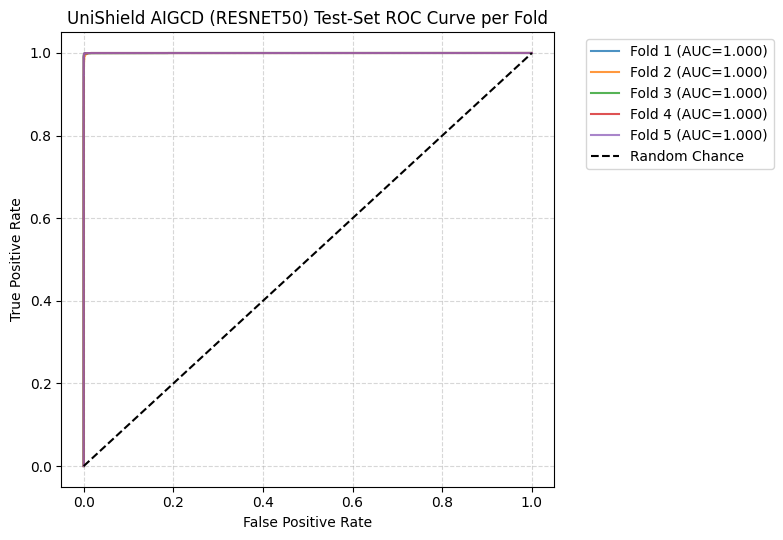

In [6]:
plt.figure(figsize=(8, 5.5))
for i, (yt, yp) in enumerate(zip(all_y_trues, all_y_preds)):
    if len(np.unique(yt)) > 1:
        fpr, tpr, _ = roc_curve(yt, yp)
        plt.plot(fpr, tpr, alpha=0.8, label=f'Fold {i+1} (AUC={roc_auc_score(yt, yp):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Chance')
plt.title(f'UniShield AIGCD ({MODEL_CHOICE.upper()}) Test-Set ROC Curve per Fold')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/aigcd_5fold_roc.png', dpi=300, bbox_inches='tight')
plt.show()
